# Un signo recibido no identifica siempre el símbolo: probabilidad y Bayes

**Tema 4 · Apartados 4.2–4.3 · Demostración orientativa: 10–20 minutos.**

Comparar la probabilidad de transmitir −1, recibir una muestra negativa y haber transmitido −1 después de observarla.

## Cómo experimentar
Ejecuta todo de arriba abajo. Cambia un parámetro, predice qué ocurrirá y vuelve a ejecutar todas las celdas.
En Colab: *Entorno de ejecución → Ejecutar todas*. En Jupyter: *Kernel → Restart Kernel and Run All Cells*.
Los comentarios `#@param` permiten formularios en Colab; en Jupyter puedes editar los valores.

En la web, «Abrir en Colab» abre este cuaderno en el navegador.
La descarga .ipynb permite abrirlo en Jupyter o importarlo en Colab.
La vista HTML muestra resultados guardados; no recalcula las gráficas. Los cambios en Colab no modifican el original.
Los datos se generan en el propio cuaderno. La semilla reproduce una realización, no elimina la variabilidad estadística.
No se instalan paquetes ni se descargan datos. Solo se necesitan NumPy y Matplotlib.

## Modelo y pregunta

Transmitimos BPSK por y=g x+b+w, con ruido gaussiano de media cero y desviación sigma.
La probabilidad previa de −1 es pi (`prob_menos`); la de +1 es 1−pi.
g es `ganancia` y t es `umbral`. El umbral t separa las observaciones:
A es «y<t». Con t=0, A significa recibir una muestra negativa.

Para cada símbolo, y tiene media g+b o −g+b y desviación sigma. Las áreas a la izquierda del umbral
en las dos densidades son P(A|+1) y P(A|−1).

**Probabilidad total:** P(A)=(1−pi) P(A|+1)+pi P(A|−1).
**Bayes:** P(x=−1|A)=pi P(A|−1)/P(A).

La primera pregunta es «¿cuántas observaciones quedan bajo el umbral?»; la segunda es «de esas,
¿cuántas proceden de −1?». Cambia el denominador. Una prueba de N símbolos proporciona frecuencias.
Aquí no buscamos un umbral óptimo; interpretamos las probabilidades con un umbral elegido.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})

## Parámetros

Cambia un valor cada vez. Los rangos y las unidades aparecen en los comentarios.

In [2]:
#@title Parámetros
ganancia = 0.8 #@param {type:"slider", min:0.2, max:1.5, step:0.1}
b = 0.0 #@param {type:"slider", min:-0.8, max:0.8, step:0.1}
sigma = 0.6 #@param {type:"slider", min:0.1, max:1.2, step:0.1}
prob_menos = 0.2 #@param {type:"slider", min:0.05, max:0.95, step:0.05}
umbral = 0.0 #@param {type:"slider", min:-1.5, max:1.5, step:0.1}
n_simbolos = 10000 #@param {type:"integer"}
semilla = 2026 #@param {type:"integer"}
assert .2 <= ganancia <= 1.5 and -.8 <= b <= .8 and .1 <= sigma <= 1.2
assert .05 <= prob_menos <= .95 and -1.5 <= umbral <= 1.5
assert isinstance(n_simbolos,int) and 1000 <= n_simbolos <= 100000
assert isinstance(semilla,int) and 0 <= semilla <= 999999

## 1. Leer las áreas condicionadas
Las curvas describen y **dado cada símbolo**. No están multiplicadas por su probabilidad previa.
Cambiar pi no cambia estas curvas. Las áreas sombreadas corresponden a A={y<t}.

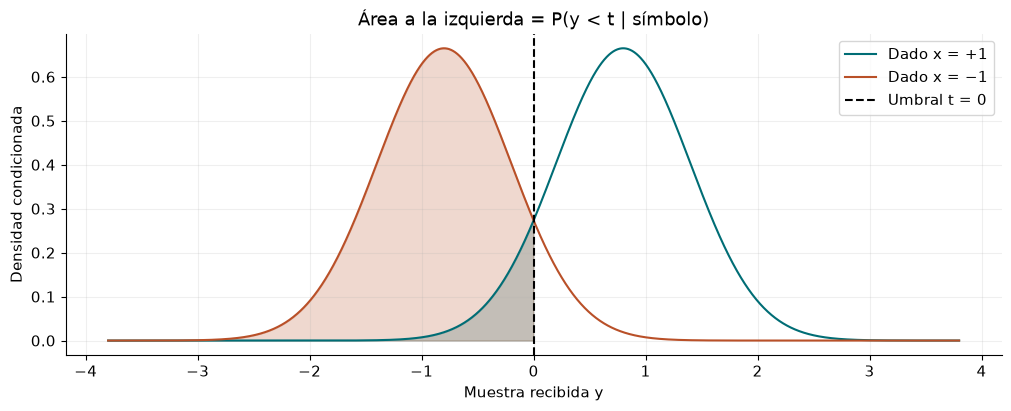

P(A | +1) = 0.09121; P(A | −1) = 0.90879.
Recuentos: filas +1/−1; columnas bajo el umbral / resto:
[[ 736 7328]
 [1751  185]]


In [3]:
mu_mas=ganancia+b;mu_menos=-ganancia+b
cdf=lambda z:.5*math.erfc(-z/math.sqrt(2))
a_mas=cdf((umbral-mu_mas)/sigma);a_menos=cdf((umbral-mu_menos)/sigma)
contrib_mas=(1-prob_menos)*a_mas;contrib_menos=prob_menos*a_menos
p_A=contrib_mas+contrib_menos;posterior=contrib_menos/p_A
rng=np.random.default_rng(semilla)
x=np.where(rng.random(n_simbolos)<prob_menos,-1,1)
w=sigma*rng.standard_normal(n_simbolos);y=ganancia*x+b+w;A=y<umbral
cuentas=np.array([[np.sum((x==1)&A),np.sum((x==1)&~A)],
                  [np.sum((x==-1)&A),np.sum((x==-1)&~A)]])
y_eje=np.linspace(min(mu_menos-5*sigma,umbral-sigma),max(mu_mas+5*sigma,umbral+sigma),2001)
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
for mu,etiqueta,color in [(mu_mas,'Dado x = +1','#006d75'),(mu_menos,'Dado x = −1','#b95028')]:
    densidad=np.exp(-.5*((y_eje-mu)/sigma)**2)/(sigma*np.sqrt(2*np.pi))
    ax.plot(y_eje,densidad,label=etiqueta,color=color)
    ax.fill_between(y_eje,densidad,where=y_eje<umbral,alpha=.22,color=color)
ax.axvline(umbral,c='black',ls='--',label=f'Umbral t = {umbral:g}')
ax.set(xlabel='Muestra recibida y',ylabel='Densidad condicionada',title='Área a la izquierda = P(y < t | símbolo)')
ax.legend();ax.grid(alpha=.2);plt.show()
print(f'P(A | +1) = {a_mas:.5f}; P(A | −1) = {a_menos:.5f}.')
print('Recuentos: filas +1/−1; columnas bajo el umbral / resto:');print(cuentas)

## 2. Cambiar el grupo sobre el que preguntamos
El primer panel descompone P(A) en dos contribuciones; sus alturas suman esa probabilidad.
El segundo compara la previa de −1 con la posterior después de observar A.
La marca naranja estima la posterior con los recuentos. Si no aparece ninguna observación A,
la posterior teórica sigue definida, pero esta prueba no permite estimarla mediante recuentos.

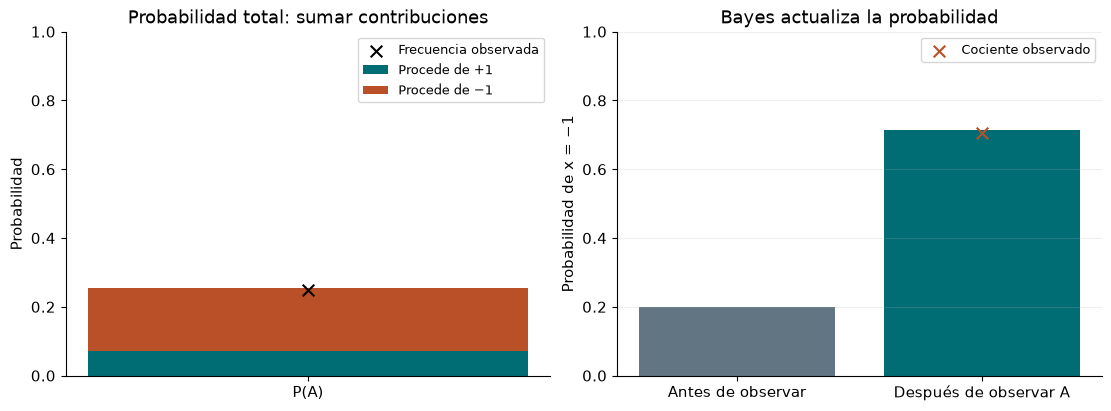

Previa: 0.20000; P(A): 0.25473; posterior teórica: 0.71354.
Prueba: 2487 de 10000 muestras bajo el umbral.
Posterior por recuentos: 0.70406.


In [4]:
n_A=int(A.sum());posterior_emp=float(np.sum((x==-1)&A)/n_A) if n_A else None
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
axes[0].bar(['P(A)'],[contrib_mas],label='Procede de +1',color='#006d75')
axes[0].bar(['P(A)'],[contrib_menos],bottom=[contrib_mas],label='Procede de −1',color='#b95028')
axes[0].scatter([0],[n_A/n_simbolos],marker='x',s=70,c='black',label='Frecuencia observada')
axes[0].set(ylim=(0,1),ylabel='Probabilidad',title='Probabilidad total: sumar contribuciones');axes[0].legend(fontsize=9)
axes[1].bar(['Antes de observar','Después de observar A'],[prob_menos,posterior],color=['#617583','#006d75'])
if posterior_emp is not None:axes[1].scatter([1],[posterior_emp],c='#b95028',marker='x',s=70,label='Cociente observado')
axes[1].set(ylim=(0,1),ylabel='Probabilidad de x = −1',title='Bayes actualiza la probabilidad');axes[1].grid(axis='y',alpha=.2)
if posterior_emp is not None:axes[1].legend(fontsize=9)
plt.show()
print(f'Previa: {prob_menos:.5f}; P(A): {p_A:.5f}; posterior teórica: {posterior:.5f}.')
print(f'Prueba: {n_A} de {n_simbolos} muestras bajo el umbral.')
print(f'Posterior por recuentos: {posterior_emp:.5f}.' if posterior_emp is not None else 'No hubo muestras bajo el umbral: cociente observado no definido.')

## Antes de mirar la explicación

1. ¿Por qué P(x=−1), P(A) y P(x=−1|A) no son la misma probabilidad?
2. Cambia la previa de 0.2 a 0.5. ¿Cambian las áreas de la primera figura? ¿Y la posterior?
3. Mueve b hacia la derecha. ¿Cómo cambia P(A) con umbral fijo?
4. ¿Una discrepancia entre recuentos y teoría demuestra que Bayes es incorrecto?

## Explicación de lo observado

1. La primera se refiere a lo enviado; la segunda, a lo observado; la tercera restringe el grupo a A.
   Los errores de signo permiten que A incluya símbolos de ambos tipos.
2. Las áreas condicionadas no cambian: medias y sigma son iguales. Sí cambian las contribuciones y la posterior.
   Con previa 0.5, b=0 y t=0, la simetría da P(A)=0.5 y la posterior es P(A|−1).
3. Ambas densidades se desplazan a la derecha: disminuye la probabilidad de quedar bajo el umbral fijo.
4. No. Los recuentos proceden de una muestra finita; con eventos raros puede faltar toda observación A.
   Hay que distinguir la probabilidad del modelo del cociente observado.

## Comprobación del modelo

Contrastamos identidades y casos conocidos; estas comprobaciones no sustituyen la interpretación.

In [5]:
assert cuentas.sum()==n_simbolos and cuentas[:,0].sum()==n_A
assert np.isclose(p_A,(1-prob_menos)*a_mas+prob_menos*a_menos)
assert np.isclose(posterior*p_A,prob_menos*a_menos)
assert 0 <= posterior <= 1 and 0 <= p_A <= 1
assert np.isclose(cdf(0),.5) and np.isclose(cdf(2)+cdf(-2),1)
if n_A:assert np.isclose(posterior_emp,cuentas[1,0]/cuentas[:,0].sum())
print('Partición de recuentos, probabilidad total y denominador de Bayes comprobados.')

Partición de recuentos, probabilidad total y denominador de Bayes comprobados.


## Referencias

Ejemplo y código propios para TDI.

- TDI, tema 4, apartados 4.2–4.3: «Probabilidad condicionada», «Hipótesis y probabilidad total» y «Bayes».
- A. Papoulis y S. U. Pillai, *Probability, Random Variables, and Stochastic Processes*: probabilidad, momentos y procesos.
- J. G. Proakis y M. Salehi, *Digital Communications*: modelos de canal y ruido.

Las condiciones y las derivaciones particulares se explican en «Modelo y pregunta».